# Day 5 · 머신러닝 4단계 (AI 모델링)
AICE 2주 합격 플랜 · 영상 5편과 함께 풉니다. 60분, 손으로 직접 치세요.
- 순서: **나누기 → 자 맞추기 → 학습(GridSearchCV) → 평가**. 공식 샘플 8~12번 형식입니다.
- GridSearchCV 는 몇십 초 걸릴 수 있어요.

_최종 수정 2026-10-20 · 바뀐 내용은 [안내 페이지의 업데이트 기록](https://pm-ainote.github.io/aice/#updates) · 개인 학습용, 재배포·판매 금지_

### 준비: 연습 데이터 내려받기
아래 셀을 먼저 실행하세요. 같은 폴더에 `aice_practice.csv` 가 생깁니다.

In [1]:
!wget -q -O aice_practice.csv https://raw.githubusercontent.com/pm-ainote/aice/main/data/aice_practice.csv
import os
print('준비 완료' if os.path.exists('aice_practice.csv') and os.path.getsize('aice_practice.csv') > 0 else '내려받기 실패: 이 셀을 다시 실행하세요')

준비 완료


### 준비: 3편에서 배운 결측치 채우기와 인코딩 (이상치는 지우지 않습니다. 실행만 하세요)

In [2]:
import pandas as pd
import numpy as np
df = pd.read_csv('aice_practice.csv')
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df = pd.get_dummies(data=df, columns=['Sex', 'Embarked'])
df.shape

(600, 9)

## 1. [직접 작성] Survived 를 답 y 로, 나머지 컬럼을 힌트 X 로 나누세요
- X 의 컬럼 개수를 `답안1` 에 저장하세요.

In [9]:
X = df.drop('Survived', axis=1)
y = df['Survived']
답안1 = X.shape[1]
답안1

8

## 2. [직접 작성] 학습용과 검증용을 70:30 으로 나누세요 (샘플 8번 형식)
- 변수: `X_train, X_valid, y_train, y_valid`
- 난수 시드 7, 답(y)의 비율을 양쪽에 똑같이 하는 옵션을 쓰세요.
- 검증용 행 개수를 `답안2` 에 저장하세요.

In [14]:
from sklearn.model_selection import train_test_split
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.3, random_state=7, stratify=y)
답안2 = len(X_valid)
답안2

180

## 3. [오류 정정] 스케일링 코드에 평가를 망치는 실수가 있습니다 (샘플 9번 형식)
- 에러는 안 납니다. 고친 뒤 스케일링된 검증 데이터의 최댓값을 반올림해 `답안3` 에 저장하세요.
- 이 셀은 X_train, X_valid 를 덮어씁니다. 고친 뒤 다시 실행할 때는 2번 셀부터 다시 실행하세요.

In [19]:
# 아래의 코드를 정정하고 실행하세요.
# Before
# from sklearn.preprocessing import StandardScaler
# ss = StandardScaler()
# X_train = ss.fit_transform(X_train)
# X_valid = ss.fit_transform(X_valid)
# round(np.max(X_valid))

# After
from sklearn.preprocessing import StandardScaler
ss = StandardScaler()
X_train = ss.fit_transform(X_train) # 학습용 데이터는 fit_transform
X_valid = ss.transform(X_valid) # 검증용 데이터는 transform
답안3 = round(np.max(X_valid)) # np.max() 데이터의 최댓값
답안3

5

## 4. [생각해 보기] 설정 없이 결정 트리를 학습시키고, 학습용과 검증용 정확도를 비교하세요
- 검증용 정확도를 소수 셋째 자리까지 반올림해 `답안4` 에 저장하세요.
- 난수 시드 7 (random_state=7)
- 모두 0(사망)이라고 찍었을 때의 정확도와도 비교해 보세요.

In [21]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(random_state=7) # 난수 시드 7
dt.fit(X_train, y_train)
print('학습용', dt.score(X_train, y_train), '검증용', dt.score(X_valid, y_valid), '찍기', y_valid.mean()) # y_valid.mean() 모두 0(사망)으로 찍었을 때 정확도
답안4 = round(dt.score(X_valid, y_valid), 3) # 검증용 정확도를 소수 셋째 자리까지 반올림
답안4

학습용 1.0 검증용 0.5055555555555555 찍기 0.45


0.506

## 5. [직접 작성] 결정 트리의 하이퍼파라미터를 GridSearchCV 로 찾고 `gs_dt` 에 저장하세요 (샘플 10번 형식)
- 최대 깊이 후보 [3, 5, 7, 10], min_samples_split 후보 [2, 3, 5, 10]
- 교차 검증 3회, scoring 은 'accuracy', n_jobs 는 -1
- 찾은 최적 최대 깊이를 `답안5` 에 저장하세요.

In [23]:
from sklearn.model_selection import GridSearchCV
param_grid_dt = {'max_depth':[3, 5, 7, 10], 'min_samples_split':[2, 3, 5, 10]}
# 최대 깊이 후보 [3, 5, 7, 10], min_samples_split 후보 [2, 3, 5, 10]
gs_dt = GridSearchCV(estimator=dt, param_grid=param_grid_dt, cv=3, scoring='accuracy', n_jobs=-1)
# 교차 검증 3회, scoring 은 'accuracy', n_jobs 는 -1
gs_dt.fit(X_train, y_train)
답안5 = gs_dt.best_params_['max_depth']
답안5

3

## 6. [직접 작성] 랜덤포레스트도 같은 방법으로 찾고 `gs_rf` 에 저장하세요 (샘플 10번 형식)
- n_estimators 후보 [100, 200, 500], 최대 깊이 후보 [5, 10, 20], min_samples_split 후보 [2, 5, 10], 난수 시드 7
- best_estimator_ 를 출력해 보고, 최적 분류기 개수(n_estimators, 나무 그루 수)를 `답안6` 에 저장하세요.

In [24]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(random_state=7) # 난수시드 7
param_grid_rf = {'n_estimators':[100, 200, 500], 'max_depth':[5, 10, 20], 'min_samples_split':[2, 5, 10]}
gs_rf = GridSearchCV(estimator=rf, param_grid=param_grid_rf, cv=3, scoring='accuracy', n_jobs=-1)
gs_rf.fit(X_train, y_train)
print(gs_rf.best_estimator_)
답안6 = gs_rf.best_params_['n_estimators']
답안6

RandomForestClassifier(max_depth=5, min_samples_split=5, random_state=7)


100

## 7. [오류 정정] 두 모델의 정확도를 구하려는데 에러가 납니다 (샘플 12번 형식)
- GridSearchCV 로 찾은 최적 모델(best_estimator_)을 쓰세요.
- 더 정확한 모델 이름을 `답안7` 에 저장하세요 ('DecisionTree' 또는 'RandomForest').

In [27]:
# 아래의 코드를 정정하고 실행하세요.
from sklearn.metrics import accuracy_score
y_pred_dt = gs_dt.best_estimator_.predict(X_valid)
y_pred_rf = gs_rf.best_estimator_.predict(X_valid)
dt_acc = accuracy_score(y_valid, y_pred_dt)
rf_acc = accuracy_score(y_valid, y_pred_rf)
print(dt_acc, rf_acc)
답안7 = 'RandomForest' if rf_acc > dt_acc else 'DecisionTree'
답안7

0.6277777777777778 0.6611111111111111


'RandomForest'

## 8. [오류 정정] 변수 중요도를 구하려는데 에러가 납니다 (샘플 11번 형식)
- 그래프에서 가장 높은 중요도를 보이는 컬럼 이름을 `답안8` 에 저장하세요.

'Sex_female'

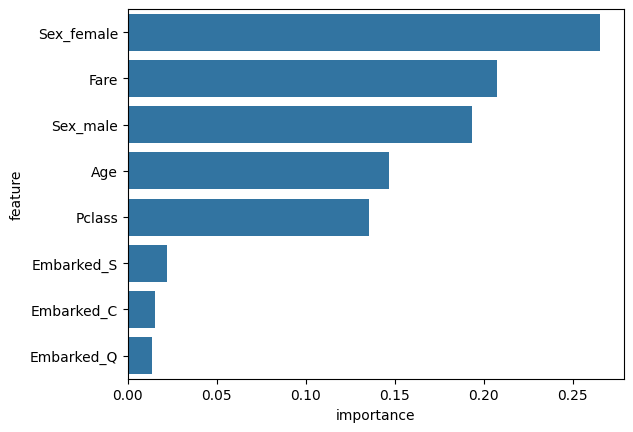

In [30]:
import seaborn as sns
# 아래의 코드를 정정하고 실행하세요.
fi = pd.DataFrame({'feature': X.columns, 'importance': gs_rf.best_estimator_.feature_importances_})
fi = fi.sort_values('importance', ascending=False)[:10]
sns.barplot(x='importance', y='feature', data=fi)
답안8 = fi.iloc[0]['feature']
답안8

## 9. [빈칸 채우기] 답(y)의 비율을 학습용과 검증용에 똑같이 나누는 옵션을 채우세요 (샘플 8번)
- 빈칸에 들어갈 말을 `답안9` 에 문자열로 저장하세요.

In [31]:
# 아래 코드의 빈칸을 채우고 실행하세요.
X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.3, random_state=7, stratify=y)
print(round(y_tr.mean(), 3), round(y_va.mean(), 3))
답안9 = 'stratify'

0.448 0.45


## 10. [빈칸 채우기] GridSearchCV 가 찾은 최적 모델을 꺼내 변수 중요도 앞 3개를 보세요 (샘플 11번)
- 빈칸에 들어갈 말을 `답안10` 에 문자열로 저장하세요.

In [32]:
# 아래 코드의 빈칸을 채우고 실행하세요.
gs_rf.best_estimator_.feature_importances_[:3]
답안10 = 'best_estimator_'

---
### 오늘의 체크 (다 푼 뒤에 보세요. 정답이 들어 있어요)
- [ ] X = df.drop(답, axis=1), y = df[답]
- [ ] train_test_split(X, y, test_size=, random_state=, stratify=y) → X_train, X_valid, y_train, y_valid
- [ ] 학습용 fit_transform, 검증용 transform
- [ ] 설정 없는 나무는 외운다(과적합) → GridSearchCV(estimator, param_grid, cv, scoring, n_jobs)
- [ ] best_estimator_ 로 꺼내서 predict, accuracy_score(정답, 예측)
- [ ] 중요도: best_estimator_.feature_importances_, 정렬은 sort_values